In [41]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.stats import linregress
from woody_filter import woody, woody_stochastic
from tqdm import tqdm

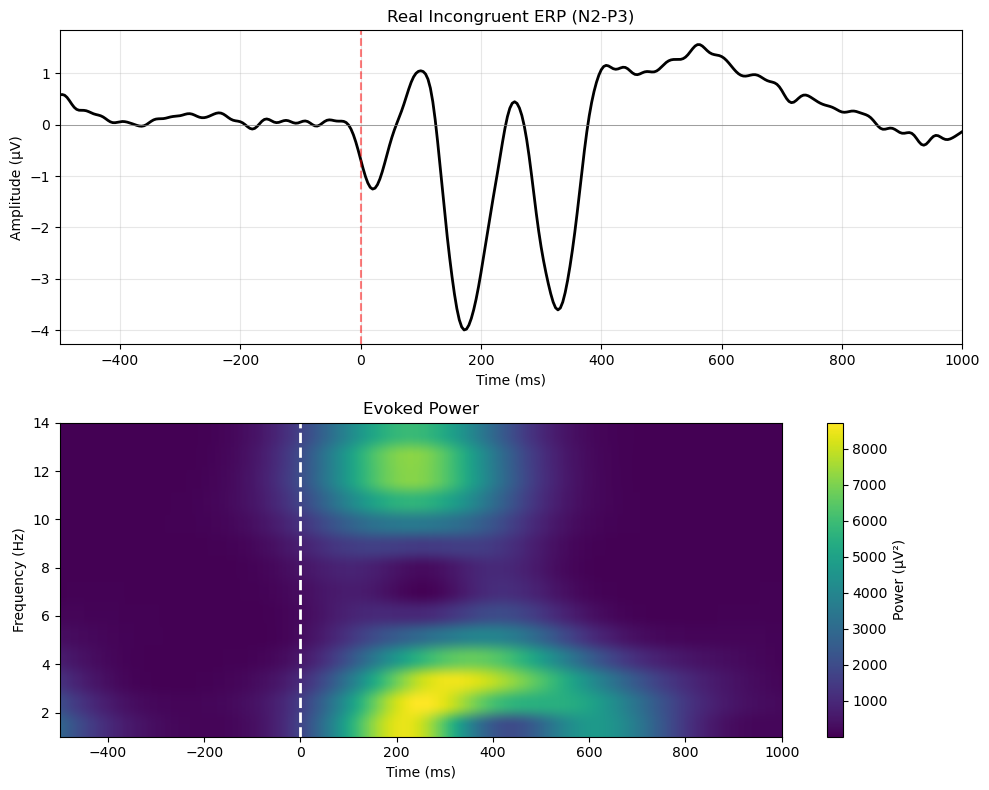

In [15]:
erp_incongruent = np.load('incong_erp_raw_mean.npy')
times = np.load('times.npy')
sfreq = 500
n_times = len(times)
tmin, tmax = times[0], times[-1]

# TFR of clean ERP
freqs = np.arange(1, 15, 1)
n_cycles = freqs / 2.0

tfr = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(erp_incongruent, wavelet, mode='same')
    tfr[idx, :] = np.abs(convolved) ** 2

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
ax1.plot(times * 1000, erp_incongruent, 'k', linewidth=2)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xlabel('Time (ms)'); ax1.set_ylabel('Amplitude (µV)')
ax1.set_title('Real Incongruent ERP (N2-P3)'); ax1.grid(alpha=0.3)
# limit time to -500 to 1000 ms
ax1.set_xlim(-500, 1000)

im = ax2.imshow(tfr, aspect='auto', origin='lower', extent=[times[0]*1000, times[-1]*1000, freqs[0], freqs[-1]])
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)'); ax2.set_ylabel('Frequency (Hz)')
ax2.set_title('Evoked Power')
ax2.set_xlim(-500, 1000)
plt.colorbar(im, ax=ax2, label='Power (µV²)')
plt.tight_layout()

Temporal jitter: M=-1.5ms, SD=15.6ms
Amplitude scaling: M=0.99, SD=0.11


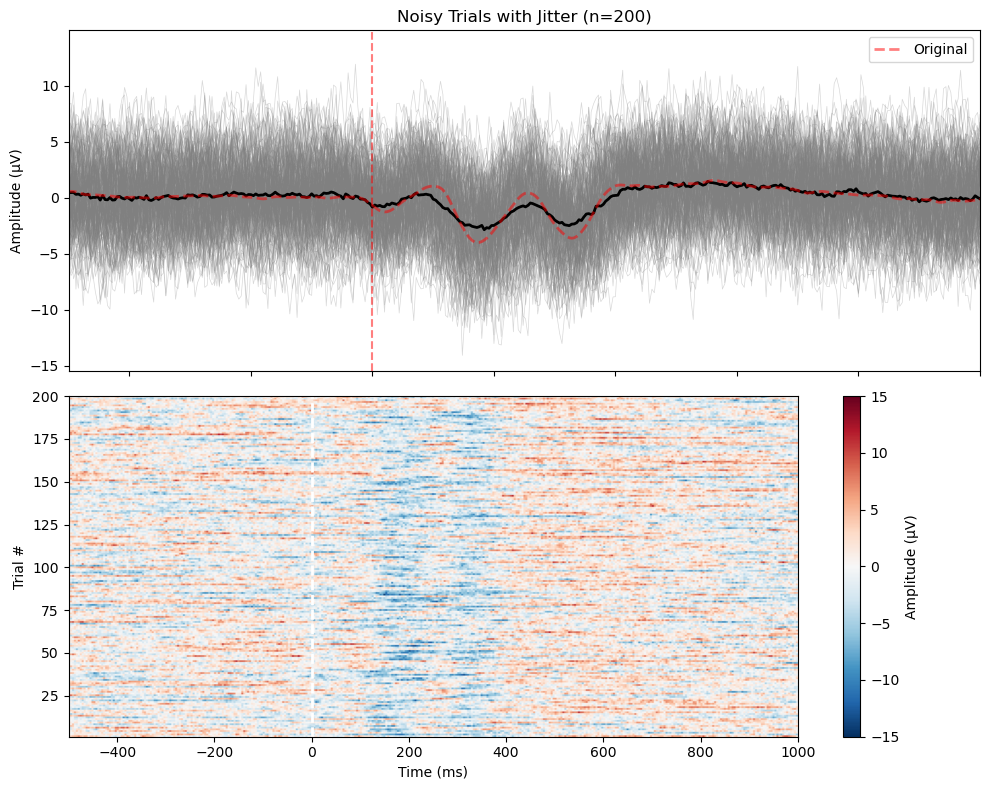

In [21]:
def generate_pink_noise(n_samples):
    white = np.random.randn(n_samples)
    fft_white = np.fft.rfft(white)
    freqs_fft = np.fft.rfftfreq(n_samples)
    freqs_fft[0] = 1
    pink_fft = fft_white / np.sqrt(freqs_fft)
    pink = np.fft.irfft(pink_fft, n=n_samples)
    return pink / np.std(pink)

n_trials = 200
jitter_sd = 0.015  # 15ms
noise_amplitude = 3
amplitude_jitter_sd = 0.10  # 20% CV

np.random.seed(42)
trials = np.zeros((n_trials, n_times))
true_jitters = np.zeros(n_trials)
amplitude_scalings = np.zeros(n_trials)

for trial in range(n_trials):
    jitter_sec = np.random.normal(0, jitter_sd)
    jitter_samples = int(jitter_sec * sfreq)
    true_jitters[trial] = jitter_sec
    
    amp_scale = np.random.normal(1.0, amplitude_jitter_sd)
    amplitude_scalings[trial] = amp_scale
    
    if jitter_samples > 0 and jitter_samples < n_times:
        shifted_erp = np.concatenate([np.zeros(jitter_samples), erp_incongruent[:-jitter_samples]])
    elif jitter_samples < 0 and -jitter_samples < n_times:
        shifted_erp = np.concatenate([erp_incongruent[-jitter_samples:], np.zeros(-jitter_samples)])
    else:
        shifted_erp = erp_incongruent.copy()
    
    shifted_erp = shifted_erp * amp_scale
    noise = generate_pink_noise(n_times) * noise_amplitude
    trials[trial, :] = shifted_erp + noise

grand_avg = trials.mean(axis=0)

print(f'Temporal jitter: M={true_jitters.mean()*1000:.1f}ms, SD={true_jitters.std()*1000:.1f}ms')
print(f'Amplitude scaling: M={amplitude_scalings.mean():.2f}, SD={amplitude_scalings.std():.2f}')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
ax1.plot(times * 1000, trials.T, 'gray', alpha=0.3, linewidth=0.5)
ax1.plot(times * 1000, grand_avg, 'k', linewidth=2)
ax1.plot(times * 1000, erp_incongruent, 'r--', linewidth=2, alpha=0.5, label='Original')
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.set_ylabel('Amplitude (µV)'); ax1.set_title(f'Noisy Trials with Jitter (n={n_trials})')
# time limit
ax1.set_xlim(-500, 1000)
ax1.legend()

im = ax2.imshow(trials, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, 1, n_trials], cmap='RdBu_r', vmin=-15, vmax=15)
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)'); ax2.set_ylabel('Trial #')
# time limit
ax2.set_xlim(-500, 1000)
plt.colorbar(im, ax=ax2, label='Amplitude (µV)')
plt.tight_layout()

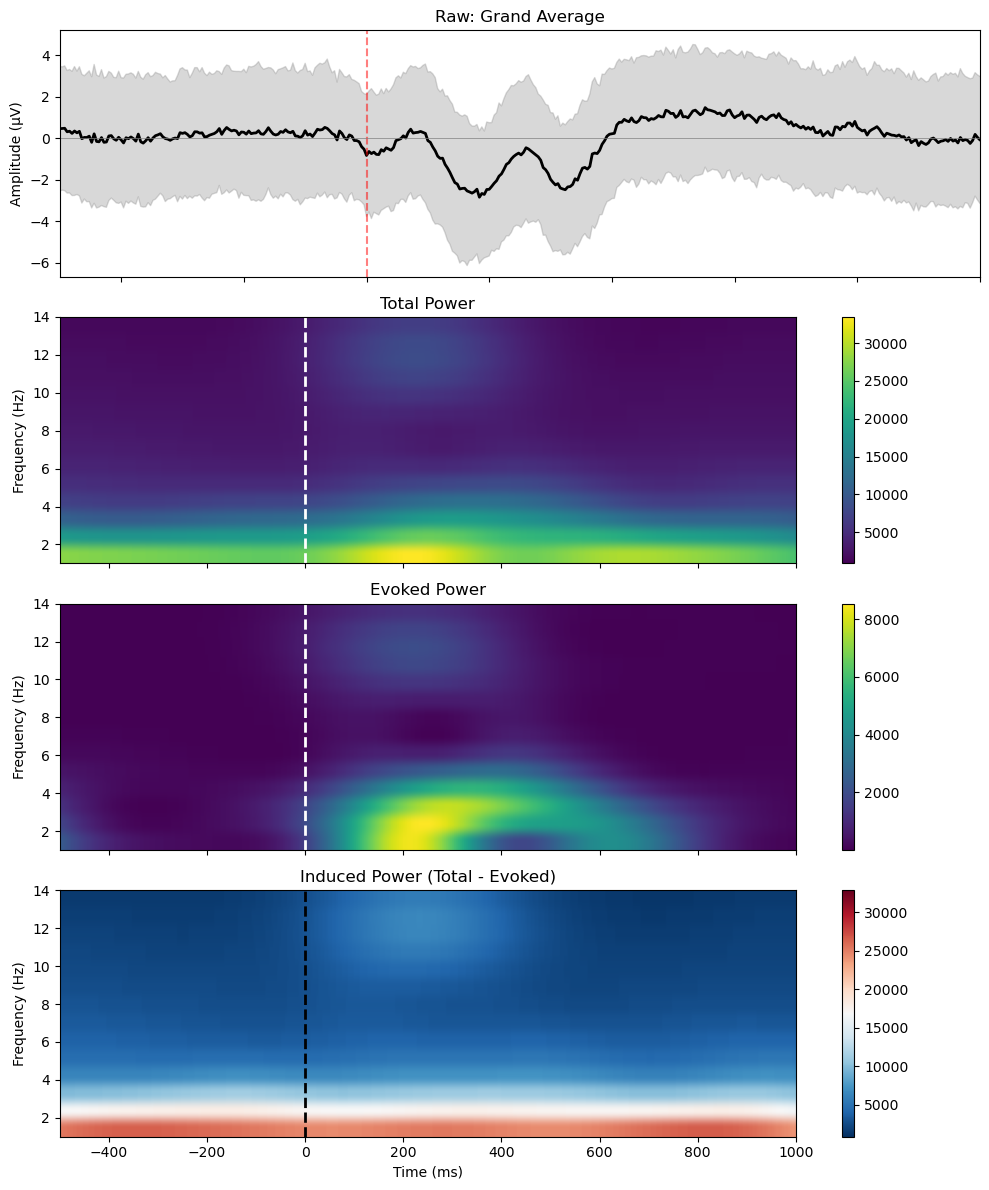

In [23]:
grand_avg = trials.mean(axis=0)
sd = trials.std(axis=0)

freqs = np.arange(1, 15, 1)
n_cycles = freqs / 2.0

# Evoked power
tfr_evoked = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg, wavelet, mode='same')
    tfr_evoked[idx, :] = np.abs(convolved) ** 2

# Total power
tfr_total = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(trials[trial, :], wavelet, mode='same')
        tfr_total[idx, :] += np.abs(convolved) ** 2
tfr_total /= n_trials

tfr_induced = tfr_total - tfr_evoked

fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)
axes[0].plot(times * 1000, grand_avg, 'k', linewidth=2)
axes[0].fill_between(times * 1000, grand_avg - sd, grand_avg + sd, color='gray', alpha=0.3)
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5); axes[0].axhline(0, color='gray', linewidth=0.5)
axes[0].set_ylabel('Amplitude (µV)'); axes[0].set_title('Raw: Grand Average')
# time limit
axes[0].set_xlim(-500, 1000)

im1 = axes[1].imshow(tfr_total, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]])
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)'); axes[1].set_title('Total Power')
# time limit
axes[1].set_xlim(-500, 1000)
plt.colorbar(im1, ax=axes[1])

im2 = axes[2].imshow(tfr_evoked, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]])
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)'); axes[2].set_title('Evoked Power')
# time limit
axes[2].set_xlim(-500, 1000)
plt.colorbar(im2, ax=axes[2])

im3 = axes[3].imshow(tfr_induced, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], cmap='RdBu_r')
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)'); axes[3].set_ylabel('Frequency (Hz)'); axes[3].set_title('Induced Power (Total - Evoked)')
plt.colorbar(im3, ax=axes[3])
plt.tight_layout()

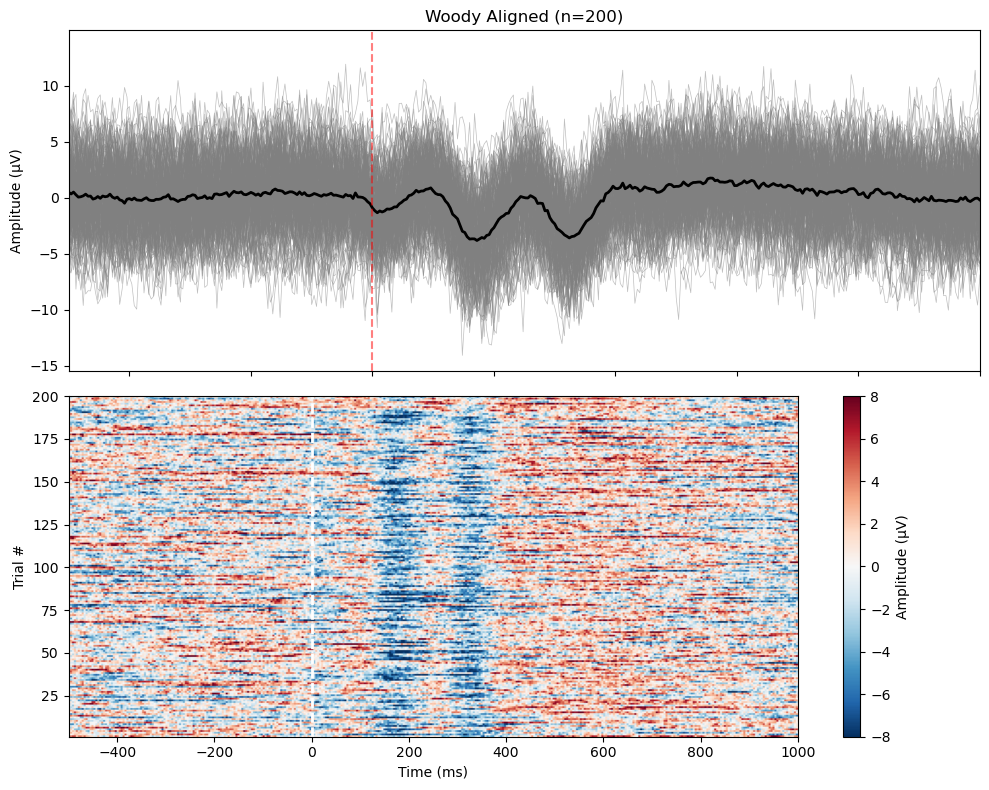

In [27]:
trials_T = trials.T
aligned_avg, detected_lags = woody(trials_T, tol=0.1, max_it=100, est_mthd='woody', xcorr_mthd='unbiased', max_shift=50)

aligned_trials = np.zeros_like(trials)
for i in range(n_trials):
    lag = detected_lags[i]
    if lag > 0:
        aligned_trials[i, :] = np.concatenate([trials[i, lag:], np.zeros(lag)])
    elif lag < 0:
        aligned_trials[i, :] = np.concatenate([np.zeros(-lag), trials[i, :lag]])
    else:
        aligned_trials[i, :] = trials[i, :]

grand_avg_aligned = aligned_trials.mean(axis=0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
ax1.plot(times * 1000, aligned_trials.T, 'gray', alpha=0.5, linewidth=0.5)
ax1.plot(times * 1000, grand_avg_aligned, 'k', linewidth=2)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.set_ylabel('Amplitude (µV)'); ax1.set_title(f'Woody Aligned (n={n_trials})')
# time limit
ax1.set_xlim(-500, 1000)

im = ax2.imshow(aligned_trials, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, 1, n_trials], cmap='RdBu_r', vmin=-8, vmax=8)
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)'); ax2.set_ylabel('Trial #')
# time limit
ax2.set_xlim(-500, 1000)
plt.colorbar(im, ax=ax2, label='Amplitude (µV)')
plt.tight_layout()

Correlation: 0.363


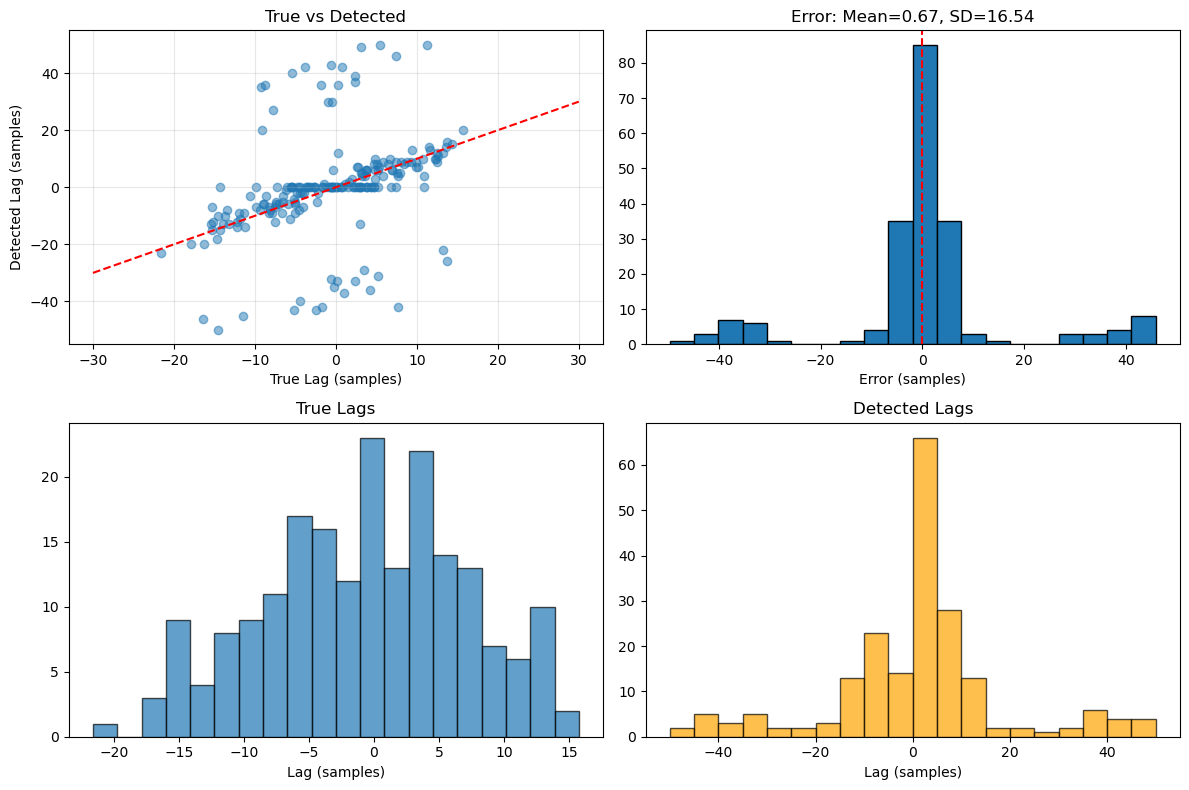

In [28]:
true_lags_samples = true_jitters * sfreq

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].scatter(true_lags_samples, detected_lags, alpha=0.5)
axes[0, 0].plot([-30, 30], [-30, 30], 'r--')
axes[0, 0].set_xlabel('True Lag (samples)'); axes[0, 0].set_ylabel('Detected Lag (samples)')
axes[0, 0].set_title('True vs Detected'); axes[0, 0].grid(alpha=0.3)

error = detected_lags - true_lags_samples
axes[0, 1].hist(error, bins=20, edgecolor='black')
axes[0, 1].axvline(0, color='r', linestyle='--')
axes[0, 1].set_xlabel('Error (samples)'); axes[0, 1].set_title(f'Error: Mean={error.mean():.2f}, SD={error.std():.2f}')

axes[1, 0].hist(true_lags_samples, bins=20, edgecolor='black', alpha=0.7)
axes[1, 0].set_xlabel('Lag (samples)'); axes[1, 0].set_title('True Lags')

axes[1, 1].hist(detected_lags, bins=20, edgecolor='black', alpha=0.7, color='orange')
axes[1, 1].set_xlabel('Lag (samples)'); axes[1, 1].set_title('Detected Lags')

plt.tight_layout()
print(f'Correlation: {np.corrcoef(true_lags_samples, detected_lags)[0,1]:.3f}')

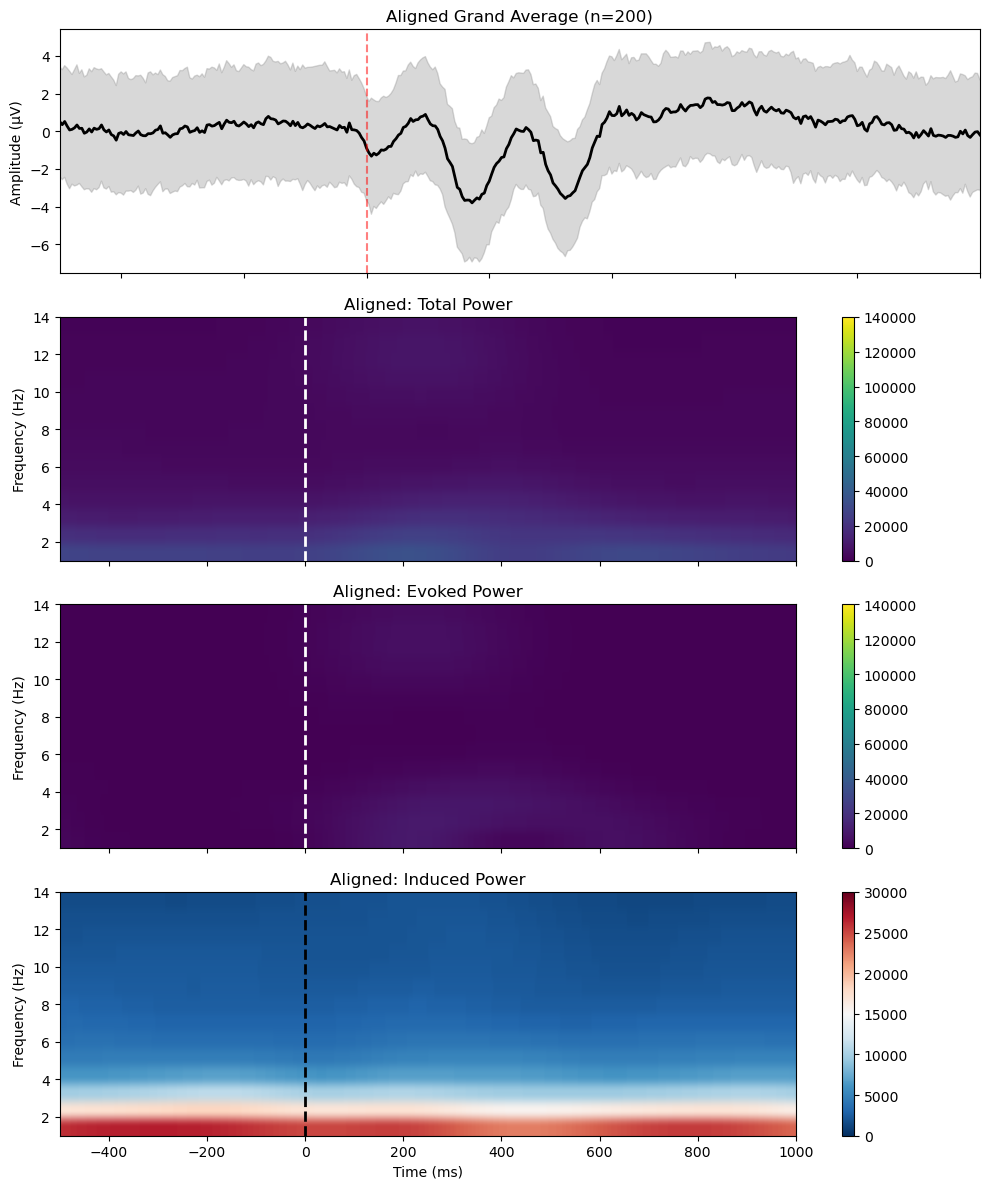

In [30]:
grand_avg_aligned = aligned_trials.mean(axis=0)
sd_aligned = aligned_trials.std(axis=0)

freqs = np.arange(1, 15, 1)
n_cycles = freqs / 2.0

tfr_evoked_aligned = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg_aligned, wavelet, mode='same')
    tfr_evoked_aligned[idx, :] = np.abs(convolved) ** 2

tfr_total_aligned = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(aligned_trials[trial, :], wavelet, mode='same')
        tfr_total_aligned[idx, :] += np.abs(convolved) ** 2
tfr_total_aligned /= n_trials

tfr_induced_aligned = tfr_total_aligned - tfr_evoked_aligned

fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)
axes[0].plot(times * 1000, grand_avg_aligned, 'k', linewidth=2)
axes[0].fill_between(times * 1000, grand_avg_aligned - sd_aligned, grand_avg_aligned + sd_aligned, color='gray', alpha=0.3)
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].set_ylabel('Amplitude (µV)'); axes[0].set_title(f'Aligned Grand Average (n={n_trials})')
# time limit
axes[0].set_xlim(-500, 1000)

im1 = axes[1].imshow(tfr_total_aligned, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], vmin=0, vmax=140000)
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)'); axes[1].set_title('Aligned: Total Power')
# time limit
axes[1].set_xlim(-500, 1000)
plt.colorbar(im1, ax=axes[1])

im2 = axes[2].imshow(tfr_evoked_aligned, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], vmin=0, vmax=140000)
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)'); axes[2].set_title('Aligned: Evoked Power')
# time limit
axes[2].set_xlim(-500, 1000)
plt.colorbar(im2, ax=axes[2])

im3 = axes[3].imshow(tfr_induced_aligned, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], cmap='RdBu_r', vmin=0, vmax=30000)
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)'); axes[3].set_ylabel('Frequency (Hz)'); axes[3].set_title('Aligned: Induced Power')
# time limit
axes[3].set_xlim(-500, 1000)
plt.colorbar(im3, ax=axes[3])
plt.tight_layout()

Run 0/1000: New best corr = 0.2122

Best correlation: 0.2125
Lag range: [-54, 56] samples
Lag std: 17.21 samples


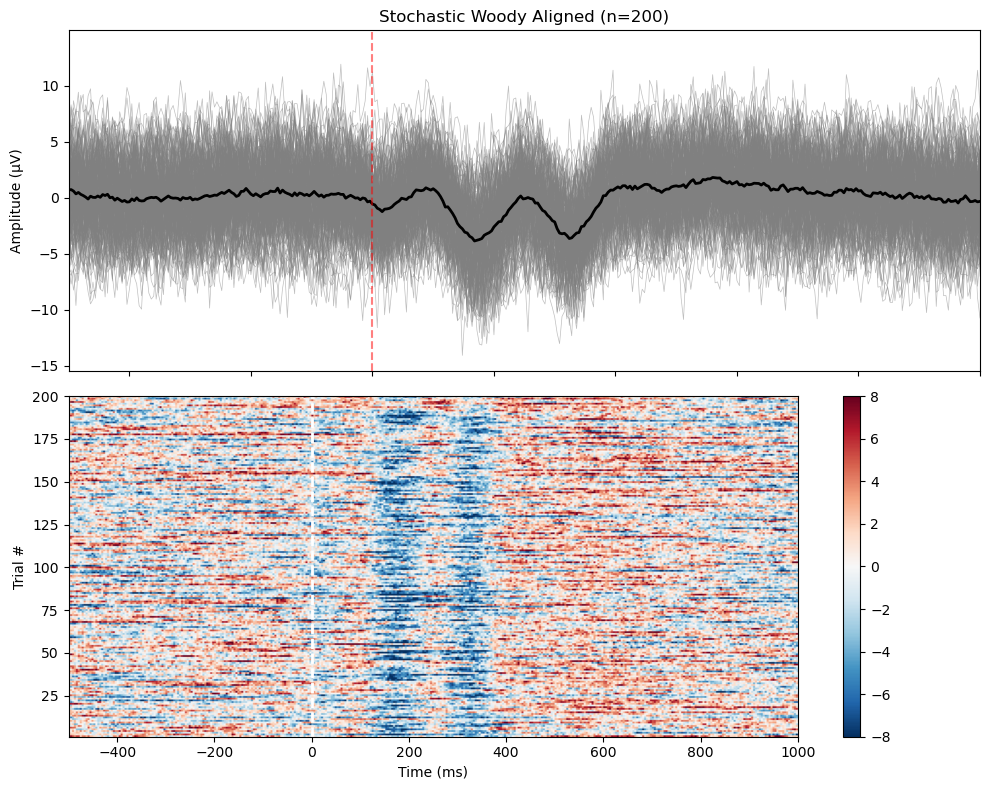

In [32]:
aligned_avg_stoch, detected_lags_stoch, best_corr = woody_stochastic(
    trials_T, tol=0.1, max_it=100, xcorr_mthd='unbiased', max_lag_init=10, max_shift=50
)

aligned_trials_stoch = np.zeros_like(trials)
for i in range(n_trials):
    lag = detected_lags_stoch[i]
    if lag > 0:
        aligned_trials_stoch[i, :] = np.concatenate([trials[i, lag:], np.zeros(lag)])
    elif lag < 0:
        aligned_trials_stoch[i, :] = np.concatenate([np.zeros(-lag), trials[i, :lag]])
    else:
        aligned_trials_stoch[i, :] = trials[i, :]

grand_avg_stoch = aligned_trials_stoch.mean(axis=0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
ax1.plot(times * 1000, aligned_trials_stoch.T, 'gray', alpha=0.5, linewidth=0.5)
ax1.plot(times * 1000, grand_avg_stoch, 'k', linewidth=2)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.set_ylabel('Amplitude (µV)'); ax1.set_title(f'Stochastic Woody Aligned (n={n_trials})')
# time limit
ax1.set_xlim(-500, 1000)

im = ax2.imshow(aligned_trials_stoch, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, 1, n_trials], cmap='RdBu_r', vmin=-8, vmax=8)
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)'); ax2.set_ylabel('Trial #')
# time limit
plt.colorbar(im, ax=ax2)
plt.tight_layout()

Correlation: 0.444


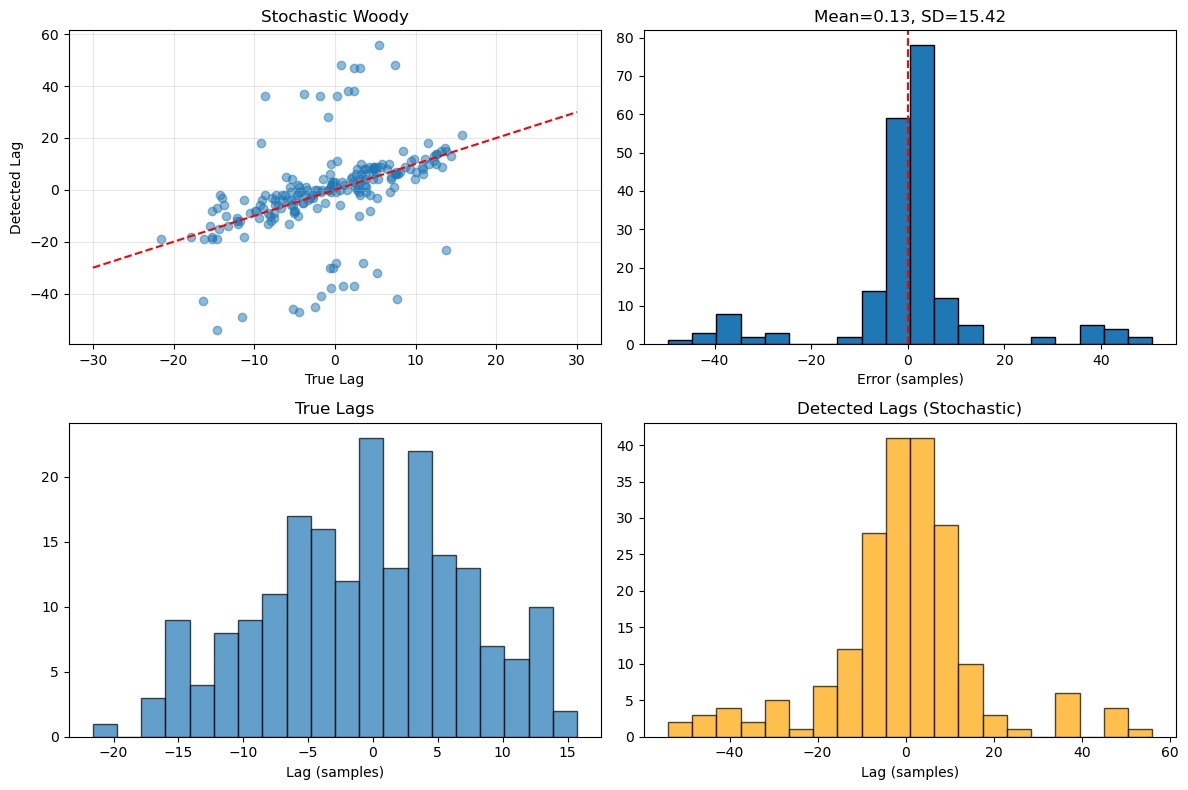

In [33]:
true_lags_samples = true_jitters * sfreq

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].scatter(true_lags_samples, detected_lags_stoch, alpha=0.5)
axes[0, 0].plot([-30, 30], [-30, 30], 'r--')
axes[0, 0].set_xlabel('True Lag'); axes[0, 0].set_ylabel('Detected Lag')
axes[0, 0].set_title('Stochastic Woody'); axes[0, 0].grid(alpha=0.3)


error_stoch = detected_lags_stoch - true_lags_samples
axes[0, 1].hist(error_stoch, bins=20, edgecolor='black')
axes[0, 1].axvline(0, color='r', linestyle='--')
axes[0, 1].set_xlabel('Error (samples)'); axes[0, 1].set_title(f'Mean={error_stoch.mean():.2f}, SD={error_stoch.std():.2f}')

axes[1, 0].hist(true_lags_samples, bins=20, edgecolor='black', alpha=0.7)
axes[1, 0].set_xlabel('Lag (samples)'); axes[1, 0].set_title('True Lags')

axes[1, 1].hist(detected_lags_stoch, bins=20, edgecolor='black', alpha=0.7, color='orange')
axes[1, 1].set_xlabel('Lag (samples)'); axes[1, 1].set_title('Detected Lags (Stochastic)')

plt.tight_layout()
print(f'Correlation: {np.corrcoef(true_lags_samples, detected_lags_stoch)[0,1]:.3f}')

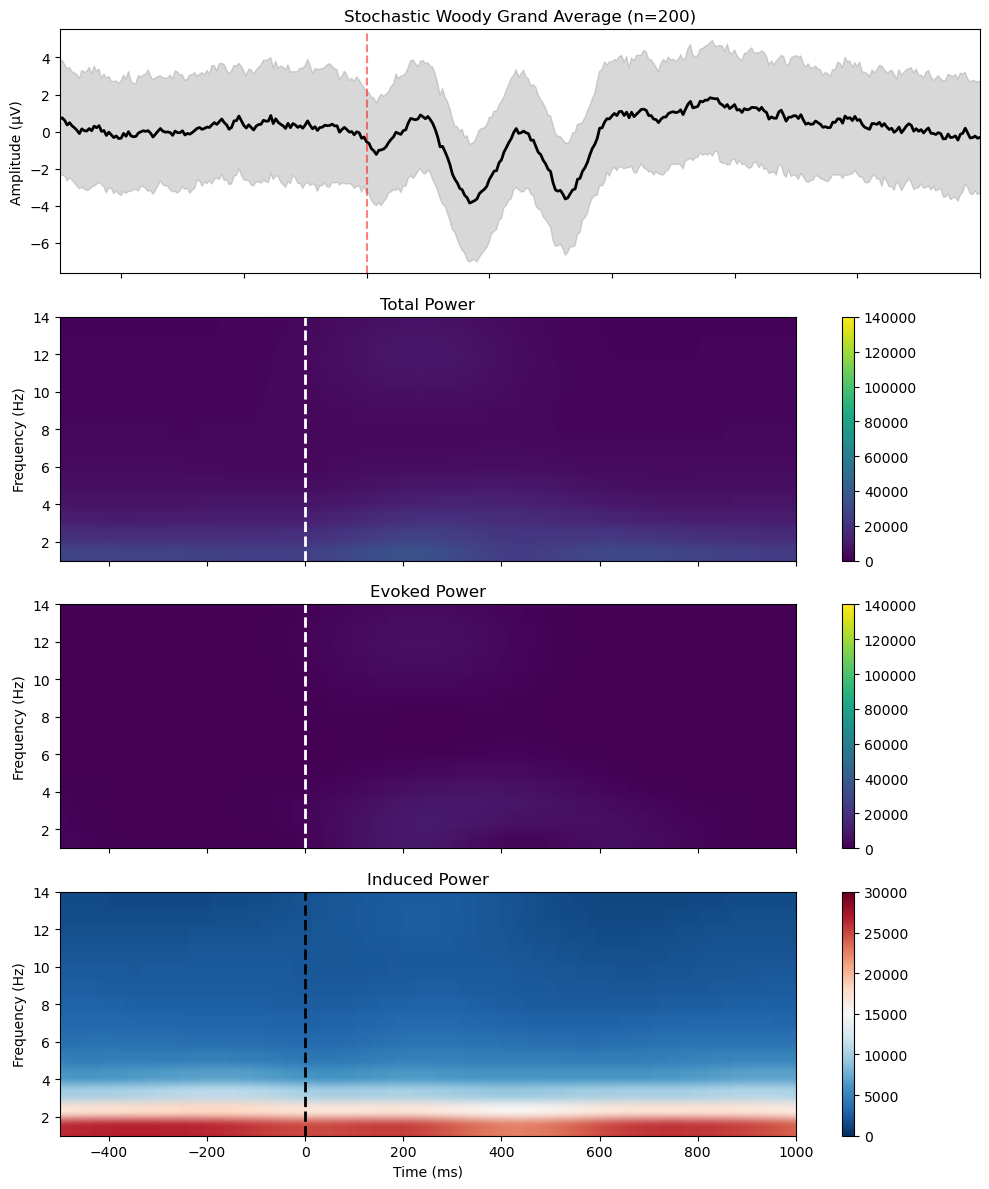

In [34]:
grand_avg_stoch = aligned_trials_stoch.mean(axis=0)
sd_stoch = aligned_trials_stoch.std(axis=0)

freqs = np.arange(1, 15, 1)
n_cycles = freqs / 2.0

tfr_evoked_stoch = np.zeros((len(freqs), len(times)))
for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
    wavelet_duration = min(3 * n_cycle / freq, 0.5)
    wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
    wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
    convolved = np.convolve(grand_avg_stoch, wavelet, mode='same')
    tfr_evoked_stoch[idx, :] = np.abs(convolved) ** 2

tfr_total_stoch = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(aligned_trials_stoch[trial, :], wavelet, mode='same')
        tfr_total_stoch[idx, :] += np.abs(convolved) ** 2
tfr_total_stoch /= n_trials

tfr_induced_stoch = tfr_total_stoch - tfr_evoked_stoch

fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)
axes[0].plot(times * 1000, grand_avg_stoch, 'k', linewidth=2)
axes[0].fill_between(times * 1000, grand_avg_stoch - sd_stoch, grand_avg_stoch + sd_stoch, color='gray', alpha=0.3)
axes[0].axvline(0, color='r', linestyle='--', alpha=0.5)
axes[0].set_ylabel('Amplitude (µV)'); axes[0].set_title(f'Stochastic Woody Grand Average (n={n_trials})')
# time limit
axes[0].set_xlim(-500, 1000)

im1 = axes[1].imshow(tfr_total_stoch, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], vmin=0, vmax=140000)
axes[1].axvline(0, color='white', linestyle='--', linewidth=2)
axes[1].set_ylabel('Frequency (Hz)'); axes[1].set_title('Total Power')
# time limit
axes[1].set_xlim(-500, 1000)
plt.colorbar(im1, ax=axes[1])

im2 = axes[2].imshow(tfr_evoked_stoch, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], vmin=0, vmax=140000)
axes[2].axvline(0, color='white', linestyle='--', linewidth=2)
axes[2].set_ylabel('Frequency (Hz)'); axes[2].set_title('Evoked Power')
# time limit
axes[2].set_xlim(-500, 1000)
plt.colorbar(im2, ax=axes[2])

im3 = axes[3].imshow(tfr_induced_stoch, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], cmap='RdBu_r', vmin=0, vmax=30000)
axes[3].axvline(0, color='black', linestyle='--', linewidth=2)
axes[3].set_xlabel('Time (ms)'); axes[3].set_ylabel('Frequency (Hz)'); axes[3].set_title('Induced Power')
# time limit
axes[3].set_xlim(-500, 1000)
plt.colorbar(im3, ax=axes[3])
plt.tight_layout()

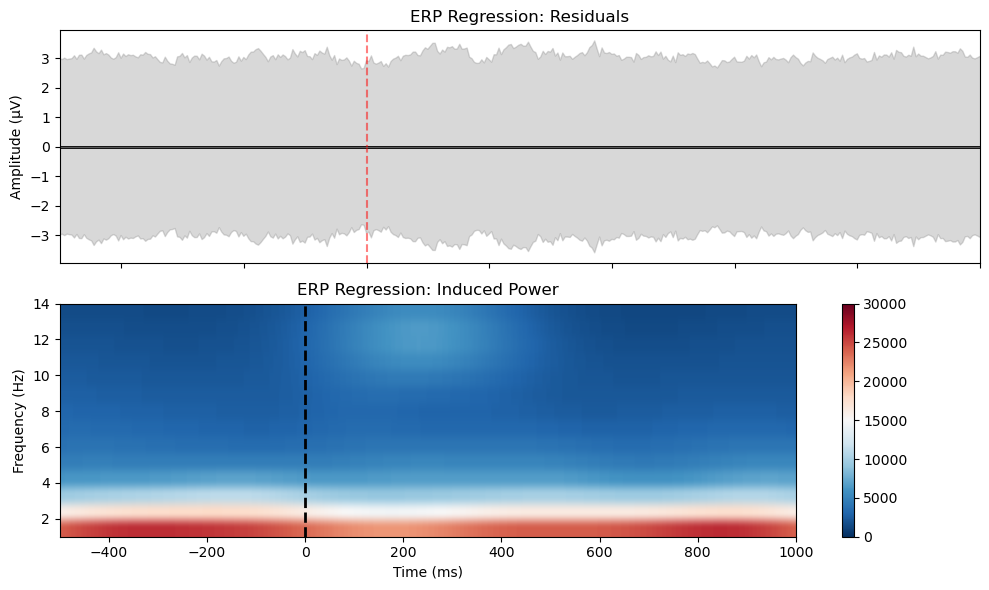

In [35]:
# Regress ERP from single trials
trials_regressed = np.zeros_like(trials)
for t_idx in range(n_trials):
    slope, intercept, _, _, _ = linregress(grand_avg, trials[t_idx, :])
    trials_regressed[t_idx, :] = trials[t_idx, :] - (intercept + slope * grand_avg)

grand_avg_reg = trials_regressed.mean(axis=0)
sd_reg = trials_regressed.std(axis=0)

# TFR on regressed trials = induced power
freqs = np.arange(1, 15, 1)
n_cycles = freqs / 2.0

tfr_induced_reg = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(trials_regressed[trial, :], wavelet, mode='same')
        tfr_induced_reg[idx, :] += np.abs(convolved) ** 2
tfr_induced_reg /= n_trials

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(times * 1000, grand_avg_reg, 'k', linewidth=2)
ax1.fill_between(times * 1000, grand_avg_reg - sd_reg, grand_avg_reg + sd_reg, color='gray', alpha=0.3)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5); ax1.axhline(0, color='gray', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)'); ax1.set_title('ERP Regression: Residuals')
# time limit
ax1.set_xlim(-500, 1000)

im = ax2.imshow(tfr_induced_reg, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], cmap='RdBu_r', vmin=0, vmax=30000)
ax2.axvline(0, color='black', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)'); ax2.set_ylabel('Frequency (Hz)'); ax2.set_title('ERP Regression: Induced Power')
# time limit
ax2.set_xlim(-500, 1000)
plt.colorbar(im, ax=ax2)
plt.tight_layout()

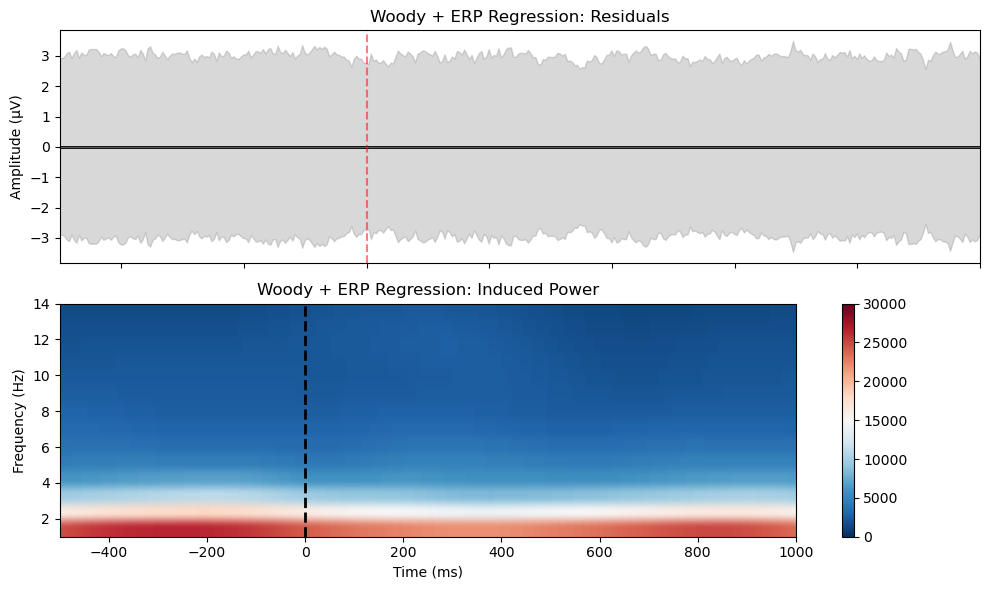

In [36]:
# Woody + ERP regression
grand_avg_aligned = aligned_trials.mean(axis=0)

trials_aligned_reg = np.zeros_like(aligned_trials)
for t_idx in range(n_trials):
    slope, intercept, _, _, _ = linregress(grand_avg_aligned, aligned_trials[t_idx, :])
    trials_aligned_reg[t_idx, :] = aligned_trials[t_idx, :] - (intercept + slope * grand_avg_aligned)

grand_avg_aligned_reg = trials_aligned_reg.mean(axis=0)
sd_aligned_reg = trials_aligned_reg.std(axis=0)

tfr_induced_aligned_reg = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(trials_aligned_reg[trial, :], wavelet, mode='same')
        tfr_induced_aligned_reg[idx, :] += np.abs(convolved) ** 2
tfr_induced_aligned_reg /= n_trials

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(times * 1000, grand_avg_aligned_reg, 'k', linewidth=2)
ax1.fill_between(times * 1000, grand_avg_aligned_reg - sd_aligned_reg, grand_avg_aligned_reg + sd_aligned_reg, color='gray', alpha=0.3)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5); ax1.axhline(0, color='gray', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)'); ax1.set_title('Woody + ERP Regression: Residuals')
# time limit
ax1.set_xlim(-500, 1000)

im = ax2.imshow(tfr_induced_aligned_reg, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], cmap='RdBu_r', vmin=0, vmax=30000)
ax2.axvline(0, color='black', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)'); ax2.set_ylabel('Frequency (Hz)'); ax2.set_title('Woody + ERP Regression: Induced Power')
# time limit
ax2.set_xlim(-500, 1000)
plt.colorbar(im, ax=ax2)
plt.tight_layout()

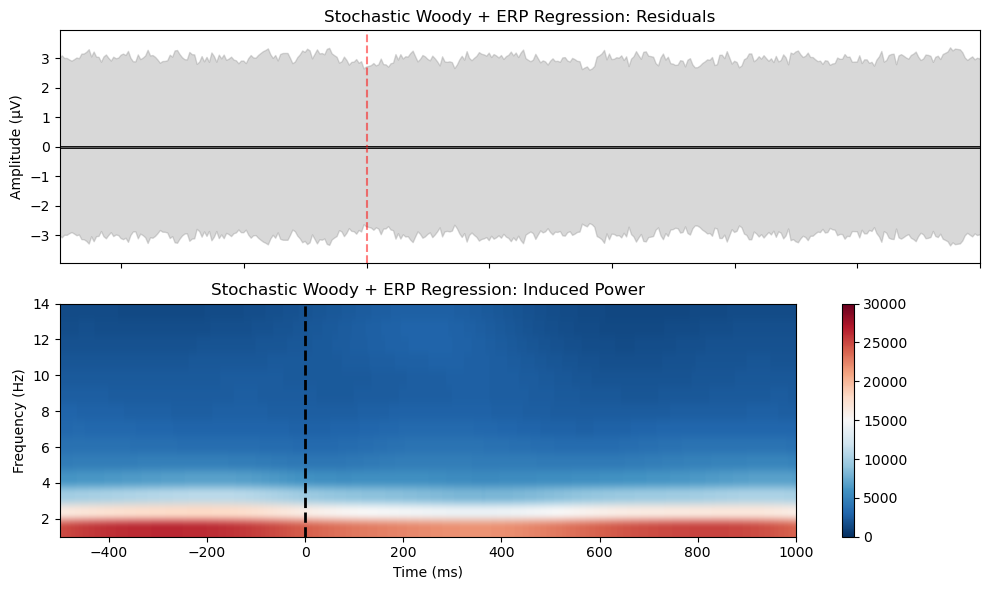

In [37]:
# Stochastic Woody + ERP regression
grand_avg_stoch = aligned_trials_stoch.mean(axis=0)

trials_stoch_reg = np.zeros_like(aligned_trials_stoch)
for t_idx in range(n_trials):
    slope, intercept, _, _, _ = linregress(grand_avg_stoch, aligned_trials_stoch[t_idx, :])
    trials_stoch_reg[t_idx, :] = aligned_trials_stoch[t_idx, :] - (intercept + slope * grand_avg_stoch)

grand_avg_stoch_reg = trials_stoch_reg.mean(axis=0)
sd_stoch_reg = trials_stoch_reg.std(axis=0)

tfr_induced_stoch_reg = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(trials_stoch_reg[trial, :], wavelet, mode='same')
        tfr_induced_stoch_reg[idx, :] += np.abs(convolved) ** 2
tfr_induced_stoch_reg /= n_trials

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(times * 1000, grand_avg_stoch_reg, 'k', linewidth=2)
ax1.fill_between(times * 1000, grand_avg_stoch_reg - sd_stoch_reg, grand_avg_stoch_reg + sd_stoch_reg, color='gray', alpha=0.3)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5); ax1.axhline(0, color='gray', linewidth=0.5)
ax1.set_ylabel('Amplitude (µV)'); ax1.set_title('Stochastic Woody + ERP Regression: Residuals')
# time limit
ax1.set_xlim(-500, 1000)

im = ax2.imshow(tfr_induced_stoch_reg, aspect='auto', origin='lower', extent=[tmin*1000, tmax*1000, freqs[0], freqs[-1]], cmap='RdBu_r', vmin=0, vmax=30000)
ax2.axvline(0, color='black', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)'); ax2.set_ylabel('Frequency (Hz)'); ax2.set_title('Stochastic Woody + ERP Regression: Induced Power')
# time limit
ax2.set_xlim(-500, 1000)
plt.colorbar(im, ax=ax2)
plt.tight_layout()

In [43]:
erp = erp_incongruent

def generate_pink_noise(n_samples):
    white = np.random.randn(n_samples)
    fft_white = np.fft.rfft(white)
    freqs_fft = np.fft.rfftfreq(n_samples)
    freqs_fft[0] = 1
    pink_fft = fft_white / np.sqrt(freqs_fft)
    pink = np.fft.irfft(pink_fft, n=n_samples)
    return pink / np.std(pink)

def compute_induced_theta(trials_data, grand_avg, times, sfreq, theta_range=(4, 8), time_window=(0, 0.5)):
    freqs = np.arange(1, 15, 1)
    n_cycles = freqs / 2.0
    n_trials = trials_data.shape[0]
    
    tfr_induced = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        residual = trials_data[trial, :] - grand_avg
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(residual, wavelet, mode='same')
            tfr_induced[idx, :] += np.abs(convolved) ** 2
    tfr_induced /= n_trials
    
    theta_mask = (freqs >= theta_range[0]) & (freqs <= theta_range[1])
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    
    return tfr_induced[theta_mask, :][:, time_mask].mean(), tfr_induced

def compute_induced_theta_regressed(trials_data, grand_avg, times, sfreq, theta_range=(4, 8), time_window=(0, 0.5)):
    freqs = np.arange(1, 15, 1)
    n_cycles = freqs / 2.0
    n_trials = trials_data.shape[0]
    
    trials_regressed = np.zeros_like(trials_data)
    for t_idx in range(n_trials):
        slope, intercept, _, _, _ = linregress(grand_avg, trials_data[t_idx, :])
        trials_regressed[t_idx, :] = trials_data[t_idx, :] - (intercept + slope * grand_avg)
    
    tfr_induced = np.zeros((len(freqs), len(times)))
    for trial in range(n_trials):
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(trials_regressed[trial, :], wavelet, mode='same')
            tfr_induced[idx, :] += np.abs(convolved) ** 2
    tfr_induced /= n_trials
    
    theta_mask = (freqs >= theta_range[0]) & (freqs <= theta_range[1])
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    
    return tfr_induced[theta_mask, :][:, time_mask].mean(), tfr_induced

def align_trials_woody(trials, detected_lags):
    n_trials, n_times = trials.shape
    aligned = np.zeros_like(trials)
    for i in range(n_trials):
        lag = detected_lags[i]
        if lag > 0:
            aligned[i, :] = np.concatenate([trials[i, lag:], np.zeros(lag)])
        elif lag < 0:
            aligned[i, :] = np.concatenate([np.zeros(-lag), trials[i, :lag]])
        else:
            aligned[i, :] = trials[i, :]
    return aligned

# SNR analysis
signal_rms = np.sqrt(np.mean(erp**2))
target_snr_db = np.linspace(-20, 10, 16)
n_trials = 200
jitter_sd = 0.040
amplitude_jitter_sd = 0.2

results = {method: [] for method in ['Raw', 'Woody', 'Stochastic Woody', 'ERP Regression', 'Woody + Reg', 'Stochastic Woody + Reg']}

for snr_db in tqdm(target_snr_db):
    snr_linear = 10**(snr_db / 20)
    noise_amp = signal_rms / snr_linear
    
    trials = np.zeros((n_trials, n_times))
    true_jitters = np.zeros(n_trials)
    
    for trial in range(n_trials):
        jitter_sec = np.random.normal(0, jitter_sd)
        jitter_samples = int(jitter_sec * sfreq)
        true_jitters[trial] = jitter_sec
        
        amp_scale = np.random.lognormal(0, amplitude_jitter_sd)
        
        if jitter_samples > 0 and jitter_samples < n_times:
            shifted_erp = np.concatenate([np.zeros(jitter_samples), erp[:-jitter_samples]])
        elif jitter_samples < 0 and -jitter_samples < n_times:
            shifted_erp = np.concatenate([erp[-jitter_samples:], np.zeros(-jitter_samples)])
        else:
            shifted_erp = erp.copy()
        
        shifted_erp = shifted_erp * amp_scale
        noise = generate_pink_noise(n_times) * noise_amp
        trials[trial, :] = shifted_erp + noise
    
    # Raw
    grand_avg_raw = trials.mean(axis=0)
    theta_raw, _ = compute_induced_theta(trials, grand_avg_raw, times, sfreq)
    results['Raw'].append(theta_raw)
    
    # Woody
    _, detected_lags = woody(trials.T, tol=0.1, max_it=100, est_mthd='woody', xcorr_mthd='unbiased', max_shift=50)
    aligned_woody = align_trials_woody(trials, detected_lags)
    grand_avg_woody = aligned_woody.mean(axis=0)
    theta_woody, _ = compute_induced_theta(aligned_woody, grand_avg_woody, times, sfreq)
    results['Woody'].append(theta_woody)
    
    # Stochastic Woody
    _, detected_lags_stoch, _ = woody_stochastic(trials.T, tol=0.1, max_it=100, n_runs=1000, max_lag_init=10, xcorr_mthd='unbiased', max_shift=50)
    aligned_stoch = align_trials_woody(trials, detected_lags_stoch)
    grand_avg_stoch = aligned_stoch.mean(axis=0)
    theta_stoch, _ = compute_induced_theta(aligned_stoch, grand_avg_stoch, times, sfreq)
    results['Stochastic Woody'].append(theta_stoch)
    
    # ERP Regression
    theta_erp_reg, _ = compute_induced_theta_regressed(trials, grand_avg_raw, times, sfreq)
    results['ERP Regression'].append(theta_erp_reg)
    
    # Woody + Regression
    theta_woody_reg, _ = compute_induced_theta_regressed(aligned_woody, grand_avg_woody, times, sfreq)
    results['Woody + Reg'].append(theta_woody_reg)
    
    # Stochastic Woody + Regression
    theta_stoch_reg, _ = compute_induced_theta_regressed(aligned_stoch, grand_avg_stoch, times, sfreq)
    results['Stochastic Woody + Reg'].append(theta_stoch_reg)

  0%|          | 0/16 [00:00<?, ?it/s]

Run 0/1000: New best corr = 0.1378

Best correlation: 0.1394
Lag range: [-58, 57] samples
Lag std: 28.88 samples


  6%|▋         | 1/16 [00:41<10:19, 41.32s/it]

Run 0/1000: New best corr = 0.1531

Best correlation: 0.1562
Lag range: [-58, 57] samples
Lag std: 30.27 samples


 12%|█▎        | 2/16 [01:50<13:26, 57.61s/it]

Run 0/1000: New best corr = 0.1741

Best correlation: 0.1781
Lag range: [-60, 56] samples
Lag std: 28.21 samples


... (23 outputs left out)

Run 0/1000: New best corr = 0.9219

Best correlation: 0.9242
Lag range: [-50, 45] samples
Lag std: 20.73 samples


 94%|█████████▍| 15/16 [16:58<01:08, 68.95s/it]

Run 0/1000: New best corr = 0.9516

Best correlation: 0.9516
Lag range: [-58, 52] samples
Lag std: 18.69 samples


100%|██████████| 16/16 [18:06<00:00, 67.88s/it]


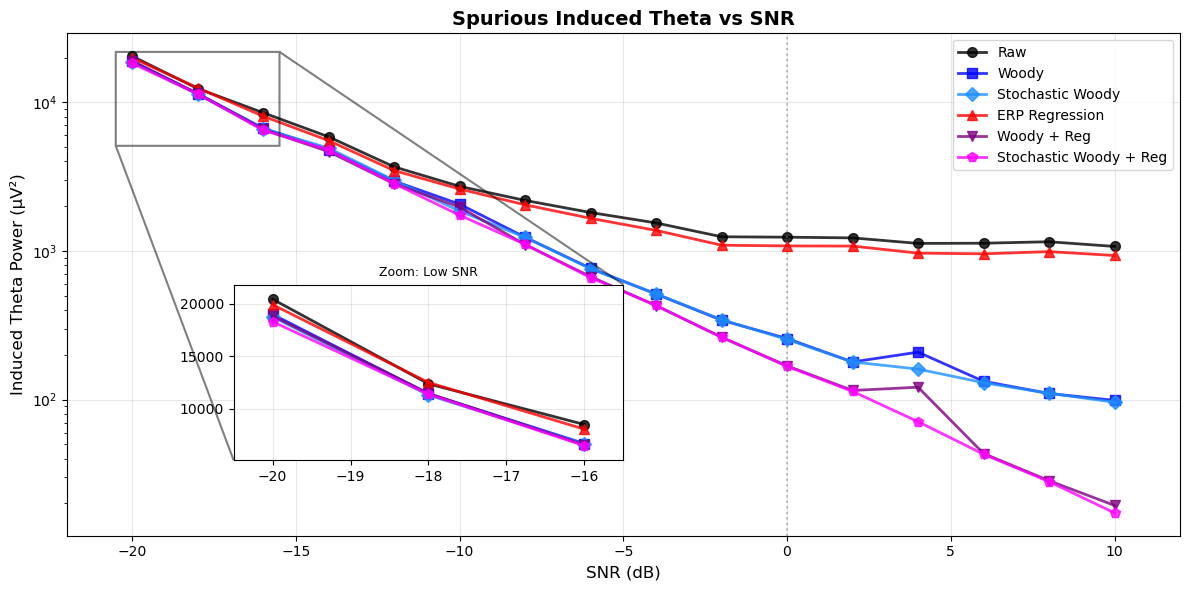

In [44]:
# Plot results - log scale with inset zoom
fig, ax = plt.subplots(figsize=(12, 6))

colors = {'Raw': 'black', 'Woody': 'blue', 'Stochastic Woody': 'dodgerblue', 
          'ERP Regression': 'red', 'Woody + Reg': 'purple', 'Stochastic Woody + Reg': 'magenta'}
markers = {'Raw': 'o', 'Woody': 's', 'Stochastic Woody': 'D', 
           'ERP Regression': '^', 'Woody + Reg': 'v', 'Stochastic Woody + Reg': 'p'}

for method in results:
    ax.semilogy(target_snr_db, results[method], marker=markers[method], color=colors[method], 
                linewidth=2, markersize=7, label=method, alpha=0.8)

ax.axvline(0, color='gray', linestyle=':', alpha=0.5)
ax.set_xlabel('SNR (dB)', fontsize=12)
ax.set_ylabel('Induced Theta Power (µV²)', fontsize=12)
ax.set_title('Spurious Induced Theta vs SNR', fontsize=14, fontweight='bold')
ax.legend(loc='upper right')
ax.grid(alpha=0.3)
ax.set_xlim(-22, 12)

# Inset zoom on first 3 values (lowest SNR)
axins = ax.inset_axes([0.15, 0.15, 0.35, 0.35])  # [x, y, width, height]
for method in results:
    axins.plot(target_snr_db[:3], results[method][:3], marker=markers[method], color=colors[method], 
               linewidth=2, markersize=7, alpha=0.8)

axins.set_xlim(target_snr_db[0] - 0.5, target_snr_db[2] + 0.5)
vals_first3 = [results[m][:3] for m in results]
ymin = min([min(v) for v in vals_first3])
ymax = max([max(v) for v in vals_first3])
margin = (ymax - ymin) * 0.1
axins.set_ylim(ymin - margin, ymax + margin)
axins.grid(alpha=0.3)
axins.set_title('Zoom: Low SNR', fontsize=9)

# Mark the zoomed region
ax.indicate_inset_zoom(axins, edgecolor='black', linewidth=1.5)

plt.tight_layout()